# COS40007 Artificial Intelligence Engineering
## Portfolio Assessment 3: Advanced ML – Classification using ML and Deep Learning
### Option 3c – LSTM for Classification

| | |
|---|---|
| **Student name** | Dinh Phu Nguyen |
| **Student ID** | 105027282 |
| **Date** | 11/1/2026 |
| **Dataset** | Appliances Energy Prediction – Candanedo, L. (2017), UCI Machine Learning Repository, DOI: [10.24432/C5VC8G](https://doi.org/10.24432/C5VC8G) |
| **GitHub** | [https://github.com/phu1009/COS40007---AI-Engineering-] |

**GenAI declaration:** I used Claude (Anthropic) in choosing option 3c, analysing the instructions and rubric and suggest the plan to do the Assignment, and organising and formatting the report. The full GenAI reflection (Part E) is in the PDF report.

## Problem definition and choice of option 3c
The dataset (cleaned in PA1, used for classification in PA2) contains **19,735 readings taken every 10 minutes** (11 January – 27 May 2016) of the appliance energy use of a low-energy house, together with indoor temperature and humidity sensors and outdoor weather data. The target is the **consumption class** defined in PA2 Task 1:

| Class | Appliances (Wh per 10 min) | Meaning (PA1 §3.3) |
|---|---|---|
| Low (0) | ≤ 50 | night-time base load |
| Medium (1) | 60–80 | light daytime activity |
| High (2) | ≥ 90 | high-power appliances, e.g. cooking in the evening peak |

The data is a **real time series** (sensor data) and the target is **categorical**, so the selection table of the instructions points to **option 3c – LSTM for Classification**.

### Design decisions kept fixed for Part A and Part B
| Decision | Choice | Reason |
|---|---|---|
| Features | 24 cleaned predictors + `hour_sin`, `hour_cos` (26) | the sensors are what the house measures; the time encoding captures the daily routine (PA2 Task 3: `hour_sin` was the most informative feature). No hand-made "change over time" features: learning temporal patterns from raw sequences is the job of the LSTM, so Part A vs Part B measures the value of temporal context |
| Split | **chronological 70/30** (train 11 Jan – 16 Apr, test 16 Apr – 27 May) | PA2 Task 10.2 showed that shuffled splits are optimistic for this time series; LSTM windows overlap, so a shuffled split would put near-identical windows in both sets |
| Test rows | the **same 5,921 test readings** for every model | fair comparison in Part C |

## 0. Setup

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # hide TensorFlow C++ info / warning messages

import time
import pickle
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, log_loss, classification_report,
                             ConfusionMatrixDisplay)
import tensorflow as tf
import keras
from keras import layers
from IPython.display import display

RANDOM_STATE = 42
TEST_SIZE = 0.30                     # chronological 70/30 split
N_FOLDS = 5                          # TimeSeriesSplit folds for Part A
CLASS_LABELS = ["Low", "Medium", "High"]
DATA_PATH = Path("data") / "energydata_complete.csv"
FIG_DIR, MODEL_DIR = Path("figures"), Path("models")
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

# Reproducibility: same seed for numpy, Python and TensorFlow, deterministic TensorFlow operations
keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()

sns.set_theme(style="whitegrid", context="notebook")
COLOR_MAIN, COLOR_SECOND, COLOR_THIRD, COLOR_GREY, COLOR_TEXT = "#2A78D6", "#E8683A", "#3A9D5D", "#B5B5AD", "#444444"
pd.set_option("display.precision", 4)


def save_fig(fig, name):
    """Save a figure for the report."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | TensorFlow {tf.__version__} | Keras {keras.__version__}")

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | TensorFlow 2.21.0 | Keras 3.15.1


# Part A – Traditional Machine Learning Models

## A.1 Load and analyse the dataset
The PA1 cleaning is applied: `date` is converted to datetime, and `rv1`, `rv2` (random noise columns, identical to each other) and `RH_6` (faulty outdoor humidity sensor) are removed. No rows are removed.

In [2]:
df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
df = df.drop(columns=["rv1", "rv2", "RH_6"])

print(f"Shape after cleaning: {df.shape[0]:,} rows x {df.shape[1]} columns | missing values: {df.isna().sum().sum()}")
print(f"Period: {df['date'].iloc[0]} to {df['date'].iloc[-1]}")
print("Time step between readings:", df["date"].diff().value_counts().to_dict())

Shape after cleaning: 19,735 rows x 26 columns | missing values: 0
Period: 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Time step between readings: {Timedelta('0 days 00:10:00'): 19734}


In [3]:
# Target: the three PA2 consumption classes (Low <= 50 Wh, Medium 60-80 Wh, High >= 90 Wh)
TARGET = "Appliances"
df["class"] = np.select([df[TARGET] <= 50, df[TARGET] <= 80], [0, 1], default=2)

# Time of day as a cyclic feature (23:50 and 00:00 are neighbours)
hour = df["date"].dt.hour + df["date"].dt.minute / 60
df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * hour / 24)

FEATURES = [c for c in df.columns if c not in ("date", TARGET, "class")]
print(f"Target '{TARGET}' is continuous (Wh), discretised into {len(CLASS_LABELS)} classes -> CLASSIFICATION problem")
print(f"{len(FEATURES)} features: {FEATURES}")

counts = df["class"].value_counts().sort_index()
display(pd.DataFrame({"class": CLASS_LABELS, "readings": counts.values,
                      "share (%)": (100 * counts / len(df)).round(1).values}).set_index("class"))

Target 'Appliances' is continuous (Wh), discretised into 3 classes -> CLASSIFICATION problem
26 features: ['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'hour_sin', 'hour_cos']


,readings,share (%)
class,,
Low,7462,37.8
Medium,6047,30.6
High,6226,31.5


## A.2 Preprocess the data
`X` and `y` are separated and split **chronologically** (`shuffle=False`): the first 70% of the period is used for training and the last 30% for testing. The **StandardScaler** is fitted on the training set only and then applied to both sets, so no information from the test period leaks into the preprocessing.

In [4]:
X = df[FEATURES].to_numpy()
y = df["class"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, shuffle=False)
CUT = len(X_train)                                     # index of the first test reading
dates_train, dates_test = df["date"].iloc[:CUT], df["date"].iloc[CUT:]

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: X {X_train_scaled.shape}, y {y_train.shape} | {dates_train.iloc[0]:%d %b %Y} – {dates_train.iloc[-1]:%d %b %Y}")
print(f"Test set:     X {X_test_scaled.shape}, y {y_test.shape} | {dates_test.iloc[0]:%d %b %Y} – {dates_test.iloc[-1]:%d %b %Y}")
print(f"Scaled training features: mean {X_train_scaled.mean():.3f}, std {X_train_scaled.std():.3f}")

split_dist = pd.DataFrame({"train (%)": 100 * np.bincount(y_train) / len(y_train),
                           "test (%)": 100 * np.bincount(y_test) / len(y_test)}, index=CLASS_LABELS).round(1)
display(split_dist)

Training set: X (13814, 26), y (13814,) | 11 Jan 2016 – 16 Apr 2016
Test set:     X (5921, 26), y (5921,) | 16 Apr 2016 – 27 May 2016
Scaled training features: mean -0.000, std 1.000


,train (%),test (%)
Low,41.5,29.3
Medium,26.9,39.4
High,31.6,31.3


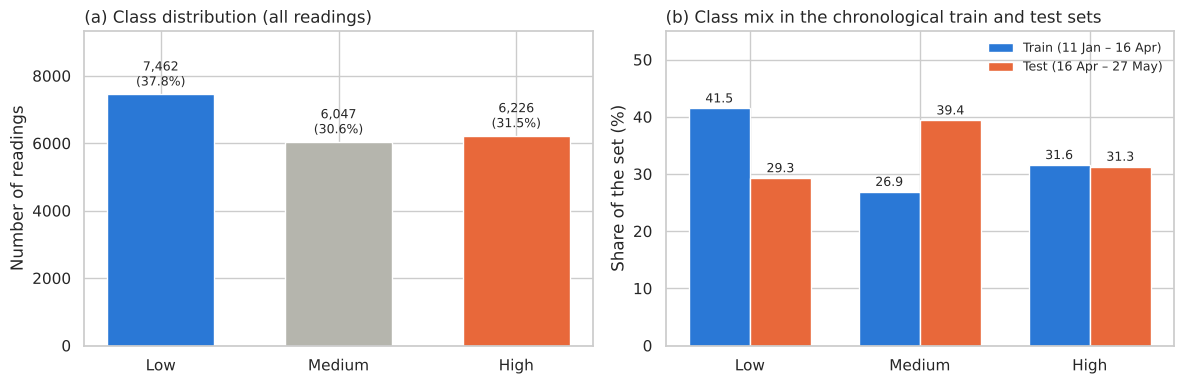

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bars = axes[0].bar(CLASS_LABELS, counts.values, color=[COLOR_MAIN, COLOR_GREY, COLOR_SECOND], width=0.6)
axes[0].bar_label(bars, labels=[f"{c:,}\n({100 * c / len(df):.1f}%)" for c in counts.values], padding=3, fontsize=9)
axes[0].set_ylim(0, counts.max() * 1.25)
axes[0].set_title("(a) Class distribution (all readings)", loc="left")
axes[0].set_ylabel("Number of readings")

x = np.arange(len(CLASS_LABELS))
b1 = axes[1].bar(x - 0.18, split_dist["train (%)"], width=0.36, color=COLOR_MAIN, label="Train (11 Jan – 16 Apr)")
b2 = axes[1].bar(x + 0.18, split_dist["test (%)"], width=0.36, color=COLOR_SECOND, label="Test (16 Apr – 27 May)")
axes[1].bar_label(b1, fmt="%.1f", padding=2, fontsize=9)
axes[1].bar_label(b2, fmt="%.1f", padding=2, fontsize=9)
axes[1].set_xticks(x, CLASS_LABELS)
axes[1].set_ylim(0, 55)
axes[1].set_ylabel("Share of the set (%)")
axes[1].set_title("(b) Class mix in the chronological train and test sets", loc="left")
axes[1].legend(frameon=False, loc="upper right", fontsize=9)
fig.tight_layout()
save_fig(fig, "pa3_A1_class_distribution")
plt.show()

### A.1–A.2 observations
- **Problem type:** the target `Appliances` is continuous, but it is used through the three PA2 classes, so this is a **3-class classification** problem. After cleaning there are 19,735 readings, 26 features and no missing values. The readings are exactly 10 minutes apart (19,734 steps of 10 minutes), so the data is a regular time series that can be cut into sequences for the LSTM.
- **Class balance:** overall 37.8% Low, 30.6% Medium and 31.5% High (balance ratio 0.81), so no class dominates.
- **Chronological split:** the 13,814 training readings cover 11 Jan – 16 Apr and the 5,921 test readings cover 16 Apr – 27 May. The **class mix shifts** between the two periods: Low falls from 41.5% to 29.3%, Medium rises from 26.9% to 39.4%, and High stays at about 31%. The most frequent training class (Low) is the least frequent test class, so the majority-class baseline only reaches 29.3%, below random guessing. Every model must cope with this seasonal shift (winter → spring), which makes the task harder than the shuffled split of PA2.
- **Scaling:** after the StandardScaler (fitted on the training set only) the training features have mean 0 and standard deviation 1. The test set is transformed with the training mean and standard deviation, as it would be for new data.

## A.3 Train two traditional ML models
| Model | Parameters | Reason |
|---|---|---|
| **Random Forest** | 300 trees, `min_samples_leaf = 5`, all features considered at random per split (`sqrt`) | averaging many de-correlated trees reduces the overfitting of the single Decision Trees in PA2 (100% training accuracy); a minimum of 5 readings per leaf smooths the leaves and keeps the saved model small |
| **MLP Classifier** | hidden layers (100, 50), ReLU, Adam, `alpha = 0.001`, `early_stopping = True`, `max_iter = 500` | starts from the course example `MLP_Classifcation.ipynb`; early stopping keeps 10% of the training data for validation and stops when it no longer improves; a small L2 penalty (`alpha`) limits overfitting |

A **majority-class baseline** (always predicts the most frequent training class) is added for reference. Both trained models and the scaler are saved as `.pkl` files.

In [6]:
models_A = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    "MLP Classifier": MLPClassifier(hidden_layer_sizes=(100, 50), activation="relu", solver="adam", alpha=1e-3,
                                    early_stopping=True, max_iter=500, random_state=RANDOM_STATE),
}

fitted_A, pred_A, proba_A, time_A = {}, {}, {}, {}
for name, model in models_A.items():
    start = time.time()
    model.fit(X_train_scaled, y_train)
    time_A[name] = time.time() - start
    fitted_A[name] = model
    pred_A[name] = model.predict(X_test_scaled)
    proba_A[name] = model.predict_proba(X_test_scaled)
    print(f"{name:18s} trained in {time_A[name]:5.1f} s")

mlp = fitted_A["MLP Classifier"]
print(f"MLP stopped after {mlp.n_iter_} iterations (best validation score {mlp.best_validation_score_:.4f})")

Majority baseline  trained in   0.0 s


Random Forest      trained in   5.3 s


MLP Classifier     trained in   6.0 s
MLP stopped after 79 iterations (best validation score 0.7685)


In [7]:
# Save the traditional models (and the scaler they need) as .pkl files
for name, filename in [("Random Forest", "random_forest.pkl"), ("MLP Classifier", "mlp_classifier.pkl")]:
    joblib.dump(fitted_A[name], MODEL_DIR / filename, compress=3)
joblib.dump(scaler, MODEL_DIR / "standard_scaler.pkl")
for f in ["random_forest.pkl", "mlp_classifier.pkl", "standard_scaler.pkl"]:
    print(f"saved models/{f} ({(MODEL_DIR / f).stat().st_size / 1e6:.2f} MB)")

saved models/random_forest.pkl (13.65 MB)
saved models/mlp_classifier.pkl (0.19 MB)
saved models/standard_scaler.pkl (0.00 MB)


## A.4 Evaluate and compare
Metrics on the test period: **accuracy**, **F1-score (weighted average)** and the test **log loss** (cross-entropy, the same loss the LSTM minimises). Cross-validation uses **5-fold `TimeSeriesSplit`** on the training period: each fold trains on the past and validates on the following block, which respects the time order (a shuffled K-fold would mix past and future readings). Inside each fold the scaler is refitted with a pipeline.

In [8]:
tscv = TimeSeriesSplit(n_splits=N_FOLDS)
rows_A = []
for name, model in models_A.items():
    cv_scores = cross_val_score(make_pipeline(StandardScaler(), clone(model)), X_train, y_train, cv=tscv,
                                scoring="accuracy", n_jobs=1)
    rows_A.append({"model": name,
                   "test_accuracy": accuracy_score(y_test, pred_A[name]),
                   "weighted_F1": f1_score(y_test, pred_A[name], average="weighted"),
                   "macro_F1": f1_score(y_test, pred_A[name], average="macro"),
                   "test_log_loss": log_loss(y_test, proba_A[name], labels=[0, 1, 2]),
                   "cv_mean": cv_scores.mean(), "cv_std": cv_scores.std(),
                   "train_accuracy": accuracy_score(y_train, fitted_A[name].predict(X_train_scaled)),
                   "train_seconds": time_A[name]})
results_A = pd.DataFrame(rows_A).set_index("model")
best_A = results_A.drop("Majority baseline")["test_accuracy"].idxmax()

table_A = results_A.copy()
table_A["CV accuracy (5-fold TimeSeriesSplit)"] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(table_A.cv_mean, table_A.cv_std)]
table_A = table_A[["test_accuracy", "weighted_F1", "macro_F1", "test_log_loss", "CV accuracy (5-fold TimeSeriesSplit)",
                   "train_accuracy", "train_seconds"]]
table_A.columns = ["Test accuracy", "Weighted F1", "Macro F1", "Test log loss", "CV accuracy (5-fold TimeSeriesSplit)",
                   "Train accuracy", "Training time (s)"]
display(table_A.style.format({c: "{:.4f}" for c in ["Test accuracy", "Weighted F1", "Macro F1", "Test log loss", "Train accuracy"]}
                             | {"Training time (s)": "{:.1f}"})
        .highlight_max(subset=["Test accuracy", "Weighted F1"], color="#d6e6f8"))
print(f"Best traditional model on the test period: {best_A}")

,Test accuracy,Weighted F1,Macro F1,Test log loss,CV accuracy (5-fold TimeSeriesSplit),Train accuracy,Training time (s)
model,,,,,,,
Majority baseline,0.2930,0.1328,0.1511,25.4820,0.3850 ± 0.0547,0.4146,0.0
Random Forest,0.5128,0.5055,0.5069,0.9174,0.5903 ± 0.0371,0.8956,5.3
MLP Classifier,0.4849,0.4860,0.4857,1.4593,0.5793 ± 0.0618,0.8016,6.0


Best traditional model on the test period: Random Forest


In [9]:
for name in ["Random Forest", "MLP Classifier"]:
    print(f"--- {name} ---")
    print(classification_report(y_test, pred_A[name], target_names=CLASS_LABELS, digits=3))

--- Random Forest ---
              precision    recall  f1-score   support

         Low      0.532     0.356     0.427      1735
      Medium      0.452     0.488     0.469      2331
        High      0.570     0.691     0.625      1855

    accuracy                          0.513      5921
   macro avg      0.518     0.512     0.507      5921
weighted avg      0.513     0.513     0.506      5921

--- MLP Classifier ---
              precision    recall  f1-score   support

         Low      0.467     0.464     0.466      1735
      Medium      0.436     0.544     0.484      2331
        High      0.618     0.431     0.508      1855

    accuracy                          0.485      5921
   macro avg      0.507     0.479     0.486      5921
weighted avg      0.502     0.485     0.486      5921



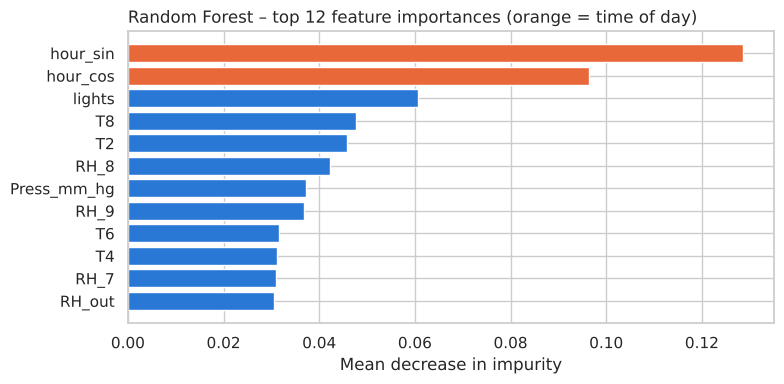

In [10]:
# Which sensors does the Random Forest rely on?
rf_importance = pd.Series(fitted_A["Random Forest"].feature_importances_, index=FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
top = rf_importance.head(12)[::-1]
ax.barh(top.index, top.values, color=[COLOR_SECOND if f.startswith("hour") else COLOR_MAIN for f in top.index])
ax.set_title("Random Forest – top 12 feature importances (orange = time of day)", loc="left")
ax.set_xlabel("Mean decrease in impurity")
fig.tight_layout()
save_fig(fig, "pa3_A4_rf_importance")
plt.show()

### A.4 – Which model performed best and why?
- **Random Forest is the best traditional model:** test accuracy **51.28%**, weighted F1 **0.506** and log loss **0.917**, compared with 48.49%, 0.486 and 1.459 for the MLP. It is also better in the time-series cross-validation (59.0% ± 3.7 vs 57.9% ± 6.2) and varies less between folds.
- **Why the Random Forest wins:**
  - It averages 300 de-correlated trees, which cancels much of the noise of a single tree (PA2 trees reached 100% training accuracy).
  - It handles skewed sensors and interactions such as *time of day × lights* without any tuning.
  - Its most important features are `hour_sin` (0.129) and `hour_cos` (0.096), together 22% of the importance, followed by `lights` (0.061) and the living-room and bedroom sensors `T8`, `T2` and `RH_8`. This matches the daily routine found in PA1 §3.3.
- **The MLP is over-confident:** its log loss (1.459) is much higher than that of the Random Forest, so its wrong predictions are made with high probability. Its internal early-stopping score was **76.9%**, because scikit-learn validates on a *random* 10% of the training rows: their 10-minute neighbours are in the training data. On the later test period it reaches only 48.5%, which shows again (as in PA2 §10.2) that shuffled validation is optimistic for time series.
- **Cross-validation vs test:** the CV scores (58–59%) are higher than the test scores (48–51%). Each CV fold validates on the block right after its training data, while the test period is later in spring and has a different class mix.
- **Overfitting:** training accuracy is 89.6% for the Random Forest and 80.2% for the MLP, far above the test accuracy.
- **Errors by class:** the Random Forest recognises High best (recall 0.69) and Low worst (0.36); many spring Low readings are predicted as Medium.

## A.5 Visualise the results

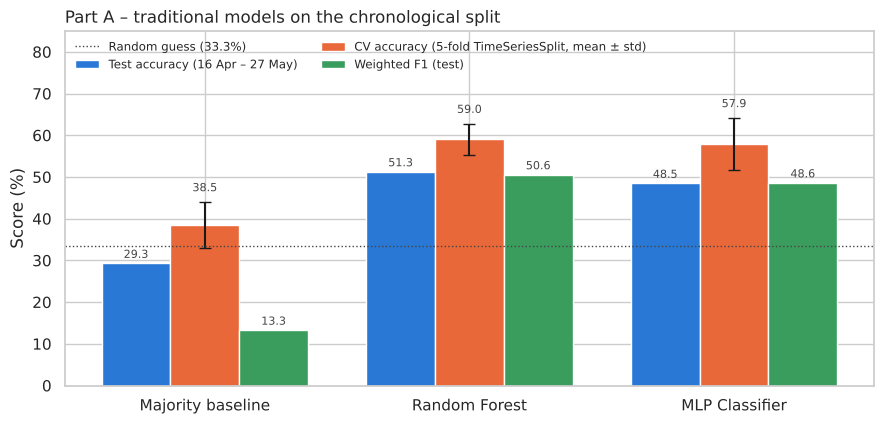

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.4))
names = results_A.index.tolist()
x = np.arange(len(names))
w = 0.26
b1 = ax.bar(x - w, results_A["test_accuracy"] * 100, width=w, color=COLOR_MAIN, label="Test accuracy (16 Apr – 27 May)")
b2 = ax.bar(x, results_A["cv_mean"] * 100, width=w, color=COLOR_SECOND, yerr=results_A["cv_std"] * 100, capsize=4,
            label="CV accuracy (5-fold TimeSeriesSplit, mean ± std)")
b3 = ax.bar(x + w, results_A["weighted_F1"] * 100, width=w, color=COLOR_THIRD, label="Weighted F1 (test)")
for b in (b1, b3):
    ax.bar_label(b, fmt="%.1f", padding=2, fontsize=8, color=COLOR_TEXT)
ax.bar_label(b2, fmt="%.1f", padding=6, fontsize=8, color=COLOR_TEXT)
ax.axhline(100 / 3, color=COLOR_TEXT, linestyle=":", linewidth=1, label="Random guess (33.3%)")
ax.set_xticks(x, names)
ax.set_ylim(0, 85)
ax.set_ylabel("Score (%)")
ax.set_title("Part A – traditional models on the chronological split", loc="left")
ax.legend(loc="upper left", frameon=False, fontsize=8.5, ncols=2)
fig.tight_layout()
save_fig(fig, "pa3_A5_traditional_comparison")
plt.show()

### A.5 observations
- Both models are far above the majority-class baseline (29.3%) and random guessing (33.3%). The Random Forest leads on all three metrics.
- In every group, the orange CV bar is 8–9 pp higher than the blue test bar. This gap measures how much harder the later, warmer test period is than the periods seen in training.
- The longer error bar of the MLP shows that its accuracy changes more from one time block to the next.

# Part B – Deep Learning: LSTM for Classification

## B.1 Prepare sequential data
**Normalisation.** The LSTM inputs are scaled to 0–1 with a `MinMaxScaler` fitted on the training period only (instructions). Test values can fall slightly outside 0–1 because the test period (spring) is warmer than the training period.

In [12]:
minmax = MinMaxScaler().fit(X_train)
X_mm = minmax.transform(X).astype("float32")          # whole series, scaled with training-period min/max
joblib.dump(minmax, MODEL_DIR / "minmax_scaler.pkl")
print(f"Training period range: {X_mm[:CUT].min():.2f} to {X_mm[:CUT].max():.2f}")
print(f"Test period range:     {X_mm[CUT:].min():.2f} to {X_mm[CUT:].max():.2f}")

Training period range: 0.00 to 1.00
Test period range:     -0.48 to 1.62


**Choice of the sequence length.** The sequence length is how many past 10-minute readings the LSTM sees before it classifies the current reading. It is chosen from how long the past stays informative in this data:

,count,mean,median,max,mean (minutes)
Low,1904,3.9,2.0,274,39.2
Medium,2581,2.3,1.0,51,23.4
High,898,6.9,3.0,76,69.3


,lag (time),autocorrelation of Appliances,P(same class as lag)
lag (steps),,,
1,10 min,0.753,0.727
3,30 min,0.438,0.647
6,1 h,0.324,0.593
12,2 h,0.311,0.535
18,3 h,0.171,0.476
36,6 h,0.021,0.360
144,24 h,0.217,0.523


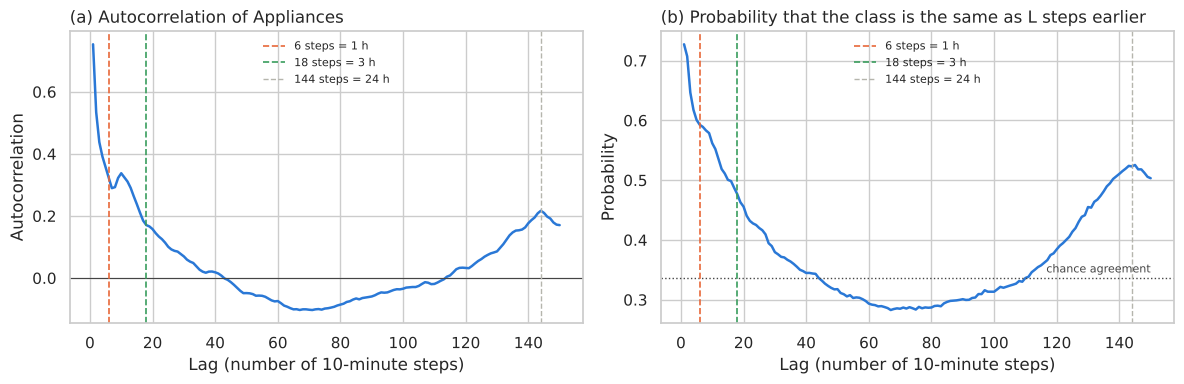

In [13]:
lags = np.arange(1, 151)
acf = np.array([df[TARGET].autocorr(l) for l in lags])
same_class = np.array([(y[l:] == y[:-l]).mean() for l in lags])

# Length of consecutive runs of the same class
run_id = (df["class"] != df["class"].shift()).cumsum()
runs = df.groupby(run_id).agg(cls=("class", "first"), length=("class", "size"))
run_table = runs.groupby("cls")["length"].agg(["count", "mean", "median", "max"])
run_table.index = CLASS_LABELS
run_table["mean (minutes)"] = run_table["mean"] * 10
display(run_table.round(1))

key = [1, 3, 6, 12, 18, 36, 144]
display(pd.DataFrame({"lag (steps)": key, "lag (time)": ["10 min", "30 min", "1 h", "2 h", "3 h", "6 h", "24 h"],
                      "autocorrelation of Appliances": acf[np.array(key) - 1].round(3),
                      "P(same class as lag)": same_class[np.array(key) - 1].round(3)}).set_index("lag (steps)"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(lags, acf, color=COLOR_MAIN, linewidth=1.8)
axes[0].axhline(0, color=COLOR_TEXT, linewidth=0.8)
axes[1].plot(lags, same_class, color=COLOR_MAIN, linewidth=1.8)
axes[1].axhline(np.sum((np.bincount(y) / len(y)) ** 2), color=COLOR_TEXT, linestyle=":", linewidth=1)
axes[1].annotate("chance agreement", xy=(150, np.sum((np.bincount(y) / len(y)) ** 2)), xytext=(0, 4),
                 textcoords="offset points", ha="right", fontsize=8, color=COLOR_TEXT)
for ax in axes:
    for L, c in [(6, COLOR_SECOND), (18, COLOR_THIRD)]:
        ax.axvline(L, color=c, linestyle="--", linewidth=1.2, label=f"{L} steps = {L * 10 // 60} h")
    ax.axvline(144, color=COLOR_GREY, linestyle="--", linewidth=1, label="144 steps = 24 h")
    ax.set_xlabel("Lag (number of 10-minute steps)")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_title("(a) Autocorrelation of Appliances", loc="left")
axes[0].set_ylabel("Autocorrelation")
axes[1].set_title("(b) Probability that the class is the same as L steps earlier", loc="left")
axes[1].set_ylabel("Probability")
fig.tight_layout()
save_fig(fig, "pa3_B1_sequence_length")
plt.show()

**Justification of the sequence length.**
- **Autocorrelation of `Appliances` (figure a):** 0.75 at 10 minutes, 0.44 at 30 minutes, 0.32 at 1 hour and 0.17 at 3 hours, then about 0 at 6 hours. It rises again to 0.22 at 24 hours because of the daily cycle, which is already given to every model through `hour_sin` and `hour_cos`.
- **Class persistence (figure b):** the class is the same as 1 hour earlier in 59% of the readings and as 3 hours earlier in 48%. At 6 hours this falls to 36%, which is the chance level (0.34).
- **Run lengths:** a High period lasts **69 minutes** on average, a Low period 39 minutes and a Medium period 23 minutes.
- **Conclusion:** the recent past is informative for about 1–3 hours, so two lengths are compared:
  - **LSTM-1 uses 6 steps (1 hour).** This covers a typical High event and the strongest part of the autocorrelation.
  - **LSTM-2 uses 18 steps (3 hours).** This goes up to the point where the autocorrelation has faded (0.17).
  - Longer windows (36+ steps) would mostly add uninformative history and multiply the training time.

**Final shapes:** training (13,809, 6, 26) and (13,797, 18, 26); test (5,921, 6, 26) and (5,921, 18, 26), i.e. (samples, timesteps, features). The test windows end on the same 5,921 readings as the Part A test set.

**Note on normalisation:** the test values lie between −0.48 and 1.62, outside the 0–1 training range (for example, spring outdoor temperatures are higher than any winter value). The LSTM has to extrapolate, which is part of the seasonal-shift problem.

**Creating the input–output pairs.** For every reading *t*, the input is the window of the last *L* feature vectors (readings *t − L + 1 … t*) and the output is the class of reading *t*. A window belongs to the training set if it ends in the training period and to the test set if it ends in the test period. Windows ending at the start of the test period use the last readings of the training period as **inputs only** (these past sensor values would be available at prediction time; no training label is used), so the LSTM is tested on **exactly the same 5,921 readings** as the Part A models.

In [14]:
SEQ_LENGTHS = {"LSTM-1": 6, "LSTM-2": 18}      # 1 hour and 3 hours of history


def make_windows(data, labels, seq_len, first_end, last_end):
    """3-D windows (samples, timesteps, features) ending at readings first_end ... last_end - 1."""
    ends = np.arange(max(first_end, seq_len - 1), last_end)
    windows = np.stack([data[e - seq_len + 1: e + 1] for e in ends])
    return windows, labels[ends], ends


seq_data = {}
for name, L in SEQ_LENGTHS.items():
    Xw_train, yw_train, _ = make_windows(X_mm, y, L, 0, CUT)
    Xw_test, yw_test, test_ends = make_windows(X_mm, y, L, CUT, len(y))
    assert np.array_equal(test_ends, np.arange(CUT, len(y)))          # same test readings as Part A
    seq_data[L] = {"train": (Xw_train, yw_train), "test": (Xw_test, yw_test)}

shape_table = pd.DataFrame([{"model": n, "sequence length": L, "history": f"{L * 10} min",
                             "train shape (samples, timesteps, features)": seq_data[L]["train"][0].shape,
                             "test shape (samples, timesteps, features)": seq_data[L]["test"][0].shape}
                            for n, L in SEQ_LENGTHS.items()]).set_index("model")
display(shape_table)

,sequence length,history,"train shape (samples, timesteps, features)","test shape (samples, timesteps, features)"
model,,,,
LSTM-1,6,60 min,"(13809, 6, 26)","(5921, 6, 26)"
LSTM-2,18,180 min,"(13797, 18, 26)","(5921, 18, 26)"


## B.2 Build the LSTM architecture
Architecture as specified for classification:

| Layer | Setting | Role |
|---|---|---|
| LSTM | 64 units, `return_sequences=True` | reads the window step by step and passes the full sequence of hidden states to the next LSTM |
| Dropout | 0.2 | randomly drops 20% of the activations during training to reduce overfitting |
| LSTM | 32 units, `return_sequences=False` | summarises the sequence into one vector (its last hidden state) |
| Dropout | 0.2 | |
| Dense | 16 units, ReLU | non-linear combination of the summary |
| Dense (output) | 3 units, Softmax | probability of Low / Medium / High |

Compiled with **Adam** (learning rate 0.001), **sparse categorical crossentropy** (the labels are the integers 0/1/2) and **accuracy**.

In [15]:
N_FEATURES = len(FEATURES)
N_CLASSES = len(CLASS_LABELS)


def build_lstm(seq_len, name="lstm"):
    model = keras.Sequential([
        layers.Input(shape=(seq_len, N_FEATURES)),
        layers.LSTM(64, return_sequences=True),
        layers.Dropout(0.2),
        layers.LSTM(32, return_sequences=False),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dense(N_CLASSES, activation="softmax"),
    ], name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


summary_lines = []
build_lstm(SEQ_LENGTHS["LSTM-1"], name="LSTM_1_seq6").summary(print_fn=lambda line, **kw: summary_lines.append(line))
print("\n".join(summary_lines))
_ = (FIG_DIR / "pa3_B2_model_summary.txt").write_text("\n".join(summary_lines), encoding="utf-8")   # kept for the report

Model: "LSTM_1_seq6"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 6, 64)          │        23,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────

- **Parameters:** 36,291 trainable parameters.
  - First LSTM: 4 gates × (64 × (26 inputs + 64 recurrent) + 64 biases) = 23,296.
  - Second LSTM: 4 × (32 × (64 + 32) + 32) = 12,416.
  - Dense layers: 528 + 51.
- **Sequence length does not change the parameter count:** the same LSTM weights are applied at every time step. LSTM-1 and LSTM-2 therefore have the same 36,291 parameters; a longer window only costs more computation per sample.
- **Shapes:** `return_sequences=True` makes the first LSTM pass its full output (6 × 64 for LSTM-1) to the second LSTM, which returns only its final state (32 values) to the dense layers.
- **Overfitting risk:** there are about 2.6 parameters per training window (36,291 vs 13,809), so overfitting is a real risk. This is why dropout and early stopping are used.

## B.3 Train the model
Training settings (instructions):
- **Validation split 20%** of the training windows. Keras takes the *last* 20% (28 Mar – 16 Apr), so validation is always later than training, as in real use.
- **EarlyStopping** on `val_loss` with patience 10 and `restore_best_weights=True`.
- **ReduceLROnPlateau** on `val_loss`: the learning rate is halved after 5 epochs without improvement.
- **Epochs:** first a 10-epoch run to check that the model learns, then up to 50 epochs with the callbacks.
- **Batch size:** 16, 32 and 64 are compared.

In [16]:
EPOCHS = 50


def make_callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)]


def train_lstm(seq_len, batch_size, epochs=EPOCHS, seed=RANDOM_STATE, callbacks=True, name="lstm"):
    """Build and train one LSTM; returns the model, its history (dict) and the training time."""
    keras.utils.set_random_seed(seed)
    Xw, yw = seq_data[seq_len]["train"]
    model = build_lstm(seq_len, name=name)
    start = time.time()
    hist = model.fit(Xw, yw, validation_split=0.2, epochs=epochs, batch_size=batch_size,
                     callbacks=make_callbacks() if callbacks else None, verbose=0)
    return model, hist.history, time.time() - start


def summarise_history(h):
    best = int(np.argmin(h["val_loss"]))
    return {"epochs run": len(h["val_loss"]), "best epoch": best + 1, "best val_loss": h["val_loss"][best],
            "val_accuracy at best": h["val_accuracy"][best], "train_accuracy at best": h["accuracy"][best],
            "final learning rate": h.get("learning_rate", [np.nan])[-1]}


# Step 1: a first 10-epoch run without callbacks, to check that the model is learning
_, h10, t10 = train_lstm(SEQ_LENGTHS["LSTM-1"], 32, epochs=10, callbacks=False, name="check_10_epochs")
display(pd.DataFrame(h10, index=pd.RangeIndex(1, 11, name="epoch")).round(4))
print(f"10 epochs in {t10:.0f} s")

,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.5936,0.8724,0.5521,0.8672
2,0.6414,0.7708,0.5771,0.8848
3,0.6556,0.7427,0.5706,0.8547
4,0.6654,0.7210,0.5710,0.8517
5,0.6773,0.7078,0.5648,0.8546
6,0.6778,0.7008,0.5626,0.8587
7,0.6856,0.6893,0.5594,0.8754
8,0.6876,0.6845,0.5634,0.8741
9,0.6944,0.6789,0.5514,0.9097


10 epochs in 43 s


**10-epoch check:**
- **The model learns:** training loss falls steadily (0.872 → 0.668) and training accuracy rises (59.4% → 70.1%).
- **Validation does not follow:** validation loss is lowest at epoch 4 (0.852) and then rises to 0.895, while validation accuracy stays at 55–58%. The model starts to overfit the training period after a few epochs.
- **Consequence:** training to 50 epochs without callbacks would only fit the winter data more closely. This motivates **EarlyStopping with `restore_best_weights=True`**, which keeps the weights of the best validation epoch.

,epochs run,best epoch,best val_loss,val_accuracy at best,train_accuracy at best,final learning rate,time (s),s per epoch
batch size,,,,,,,,
16,14,4,0.8444,0.5706,0.6685,0.0005,84.8060,6.0576
32,14,4,0.8517,0.5710,0.6654,0.0005,58.5085,4.1792
64,13,3,0.8358,0.5735,0.6445,0.0005,29.4907,2.2685


Chosen batch size (lowest validation loss): 64


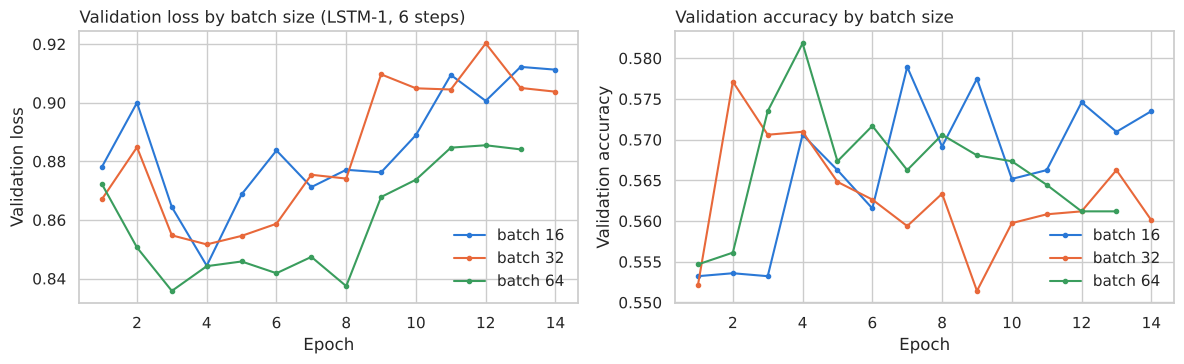

In [17]:
# Step 2: batch-size comparison (16 / 32 / 64) with up to 50 epochs and both callbacks, sequence length 6
batch_runs, batch_rows = {}, []
for bs in [16, 32, 64]:
    model, hist, secs = train_lstm(SEQ_LENGTHS["LSTM-1"], bs, name=f"LSTM_1_bs{bs}")
    batch_runs[bs] = (model, hist, secs)
    batch_rows.append({"batch size": bs, **summarise_history(hist), "time (s)": secs,
                       "s per epoch": secs / len(hist["val_loss"])})
batch_table = pd.DataFrame(batch_rows).set_index("batch size")
BEST_BATCH = int(batch_table["best val_loss"].idxmin())         # chosen on validation data, not on the test set
display(batch_table.round(4))
print(f"Chosen batch size (lowest validation loss): {BEST_BATCH}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for bs, c in zip([16, 32, 64], [COLOR_MAIN, COLOR_SECOND, COLOR_THIRD]):
    h = batch_runs[bs][1]
    ep = np.arange(1, len(h["val_loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], color=c, marker="o", markersize=3, label=f"batch {bs}")
    axes[1].plot(ep, h["val_accuracy"], color=c, marker="o", markersize=3, label=f"batch {bs}")
axes[0].set_title("Validation loss by batch size (LSTM-1, 6 steps)", loc="left")
axes[1].set_title("Validation accuracy by batch size", loc="left")
for ax, lab in zip(axes, ["Validation loss", "Validation accuracy"]):
    ax.set_xlabel("Epoch")
    ax.set_ylabel(lab)
    ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "pa3_B3_batch_size")
plt.show()

In [18]:
# Step 3: the two deep learning models of Part C
lstm_models, lstm_histories, lstm_times = {}, {}, {}
lstm_models["LSTM-1"], lstm_histories["LSTM-1"], lstm_times["LSTM-1"] = batch_runs[BEST_BATCH]   # 6 steps, chosen batch size
lstm_models["LSTM-2"], lstm_histories["LSTM-2"], lstm_times["LSTM-2"] = train_lstm(SEQ_LENGTHS["LSTM-2"], BEST_BATCH,
                                                                                   name="LSTM_2_seq18")
train_table = pd.DataFrame({n: {"sequence length": SEQ_LENGTHS[n], "batch size": BEST_BATCH,
                                **summarise_history(lstm_histories[n]), "time (s)": lstm_times[n]}
                            for n in lstm_models}).T
display(train_table)

,sequence length,batch size,epochs run,best epoch,best val_loss,val_accuracy at best,train_accuracy at best,final learning rate,time (s)
LSTM-1,6.0,64.0,13.0,3.0,0.8358,0.5735,0.6445,0.0005,29.4907
LSTM-2,18.0,64.0,14.0,4.0,0.8653,0.5627,0.6647,0.0005,55.2653


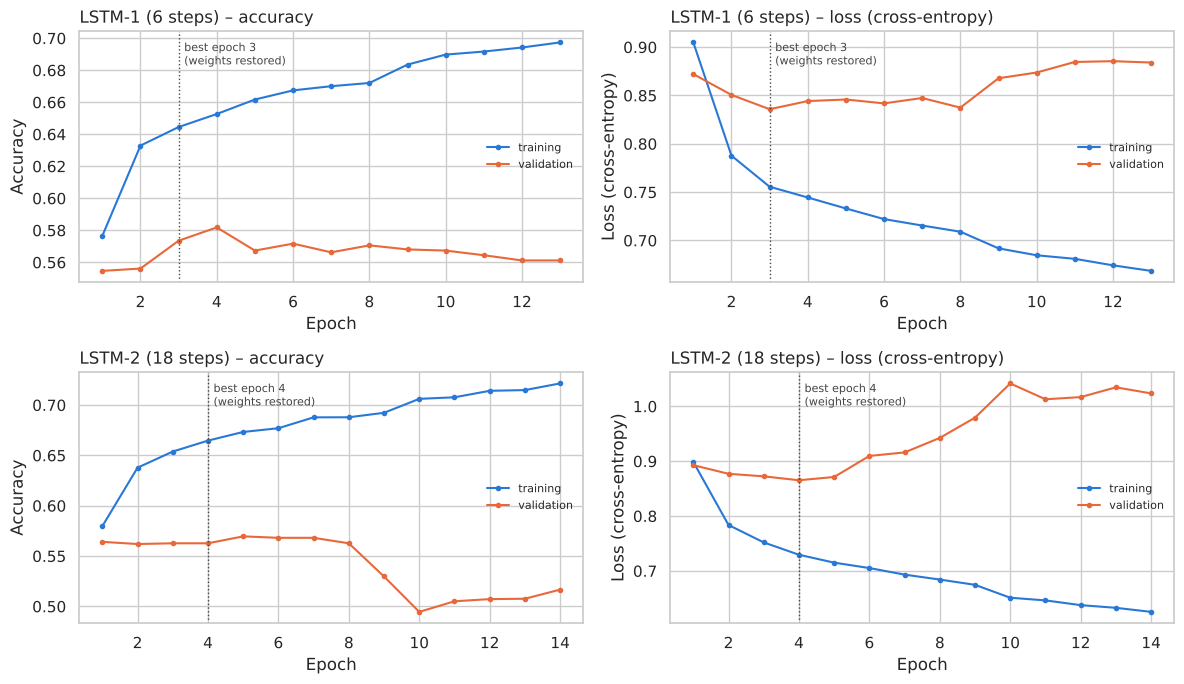

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, name in enumerate(lstm_models):
    h = lstm_histories[name]
    ep = np.arange(1, len(h["loss"]) + 1)
    best = int(np.argmin(h["val_loss"])) + 1
    for col, (metric, label) in enumerate([("accuracy", "Accuracy"), ("loss", "Loss (cross-entropy)")]):
        ax = axes[row, col]
        ax.plot(ep, h[metric], color=COLOR_MAIN, marker="o", markersize=3, label="training")
        ax.plot(ep, h[f"val_{metric}"], color=COLOR_SECOND, marker="o", markersize=3, label="validation")
        ax.axvline(best, color=COLOR_TEXT, linestyle=":", linewidth=1)
        ax.annotate(f"best epoch {best}\n(weights restored)", xy=(best, ax.get_ylim()[1]), xytext=(4, -24),
                    textcoords="offset points", fontsize=8, color=COLOR_TEXT)
        ax.set_title(f"{name} ({SEQ_LENGTHS[name]} steps) – {label.lower()}", loc="left")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.legend(frameon=False, fontsize=8, loc="center right")
fig.tight_layout()
save_fig(fig, "pa3_B3_training_curves")
plt.show()

### B.3 observations
- **Batch size:**

| Batch | Best validation loss | Training time |
|---|---|---|
| 16 | 0.844 | 85 s (6.1 s/epoch) |
| 32 | 0.852 | 59 s (4.2 s/epoch) |
| **64** | **0.836** | **29 s (2.3 s/epoch)** |

  **Batch size 64 is chosen:** it has the lowest validation loss and trains 2.9× faster than batch 16. The validation accuracy is almost the same for all three (57.1–57.4%), so smaller, noisier batches brought no benefit on this noisy target.
- **Callbacks:** every run reached its best validation loss at **epoch 3–4** and was stopped by EarlyStopping after 13–14 epochs (patience 10), with the best weights restored. ReduceLROnPlateau halved the learning rate once (0.001 → 0.0005), but the validation loss did not improve again. The limit is the difference between the training and validation periods, not the optimisation.
- **Training curves:** training accuracy keeps rising (to about 70%) while validation accuracy peaks at about 57–58% and validation loss rises after epoch 3–4. This is the typical overfitting pattern. The validation windows (the last 20% of training, 28 Mar – 16 Apr) are later and warmer than most of the training data, so what the model learns about winter only partly transfers.
- **LSTM-2 (18 steps) overfits faster:** its validation loss climbs from 0.865 to 1.04 and its validation accuracy drops to about 50% by epoch 10. It also takes 1.9× longer to train (55 s vs 29 s).

## B.4 Evaluate the LSTM models
Both LSTMs and the best Part A model are evaluated on the same 5,921 test readings (16 Apr – 27 May).

In [20]:
lstm_pred, lstm_proba, rows_B = {}, {}, []
for name, model in lstm_models.items():
    Xw_test, yw_test = seq_data[SEQ_LENGTHS[name]]["test"]
    test_loss, test_acc = model.evaluate(Xw_test, yw_test, verbose=0)
    lstm_proba[name] = model.predict(Xw_test, verbose=0)
    lstm_pred[name] = lstm_proba[name].argmax(axis=1)
    rows_B.append({"model": f"{name} ({SEQ_LENGTHS[name]} steps)", "test_accuracy": test_acc, "test_loss": test_loss,
                   "weighted_F1": f1_score(yw_test, lstm_pred[name], average="weighted"),
                   "macro_F1": f1_score(yw_test, lstm_pred[name], average="macro")})
rows_B.append({"model": f"{best_A} (best Part A)", "test_accuracy": results_A.loc[best_A, "test_accuracy"],
               "test_loss": results_A.loc[best_A, "test_log_loss"], "weighted_F1": results_A.loc[best_A, "weighted_F1"],
               "macro_F1": results_A.loc[best_A, "macro_F1"]})
results_B = pd.DataFrame(rows_B).set_index("model")
display(results_B.style.format("{:.4f}").highlight_max(subset=["test_accuracy", "weighted_F1"], color="#d6e6f8")
        .highlight_min(subset=["test_loss"], color="#d6e6f8"))

for name in lstm_models:
    print(f"--- {name} ({SEQ_LENGTHS[name]} steps) ---")
    print(classification_report(y_test, lstm_pred[name], target_names=CLASS_LABELS, digits=3))

,test_accuracy,test_loss,weighted_F1,macro_F1
model,,,,
LSTM-1 (6 steps),0.5361,0.8831,0.5235,0.5270
LSTM-2 (18 steps),0.5095,0.9130,0.5062,0.5058
Random Forest (best Part A),0.5128,0.9174,0.5055,0.5069


--- LSTM-1 (6 steps) ---
              precision    recall  f1-score   support

         Low      0.501     0.387     0.436      1735
      Medium      0.485     0.438     0.460      2331
        High      0.599     0.799     0.685      1855

    accuracy                          0.536      5921
   macro avg      0.528     0.541     0.527      5921
weighted avg      0.525     0.536     0.523      5921

--- LSTM-2 (18 steps) ---
              precision    recall  f1-score   support

         Low      0.533     0.356     0.427      1735
      Medium      0.444     0.547     0.490      2331
        High      0.595     0.605     0.600      1855

    accuracy                          0.510      5921
   macro avg      0.524     0.503     0.506      5921
weighted avg      0.517     0.510     0.506      5921



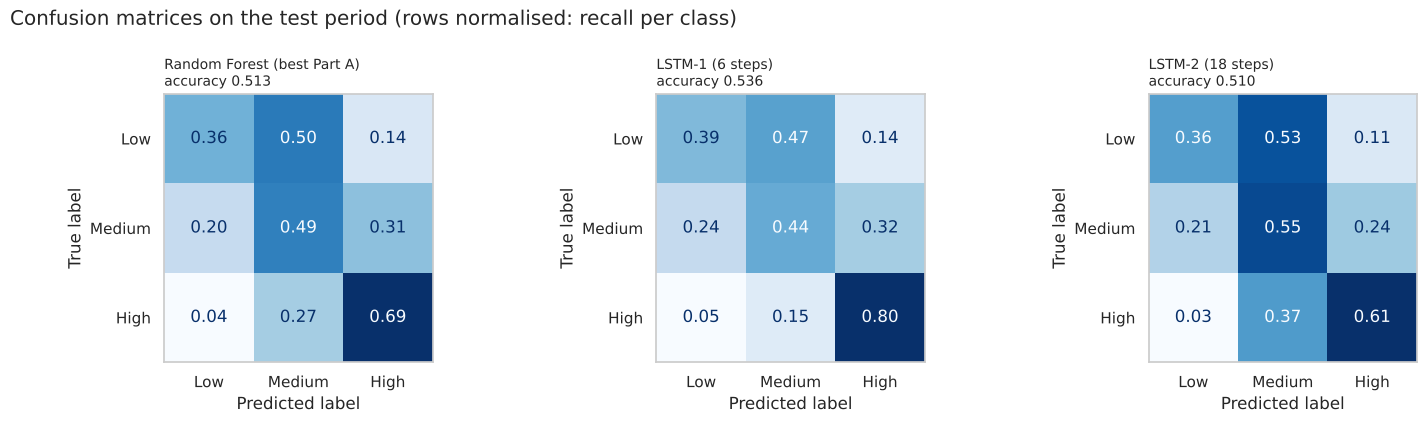

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
panels = [(f"{best_A} (best Part A)", pred_A[best_A])] + [(f"{n} ({SEQ_LENGTHS[n]} steps)", lstm_pred[n]) for n in lstm_models]
for ax, (title, pred) in zip(axes, panels):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=CLASS_LABELS, normalize="true",
                                            values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{title}\naccuracy {accuracy_score(y_test, pred):.3f}", loc="left", fontsize=10)
    ax.grid(False)
fig.suptitle("Confusion matrices on the test period (rows normalised: recall per class)", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "pa3_B4_confusion_matrices")
plt.show()

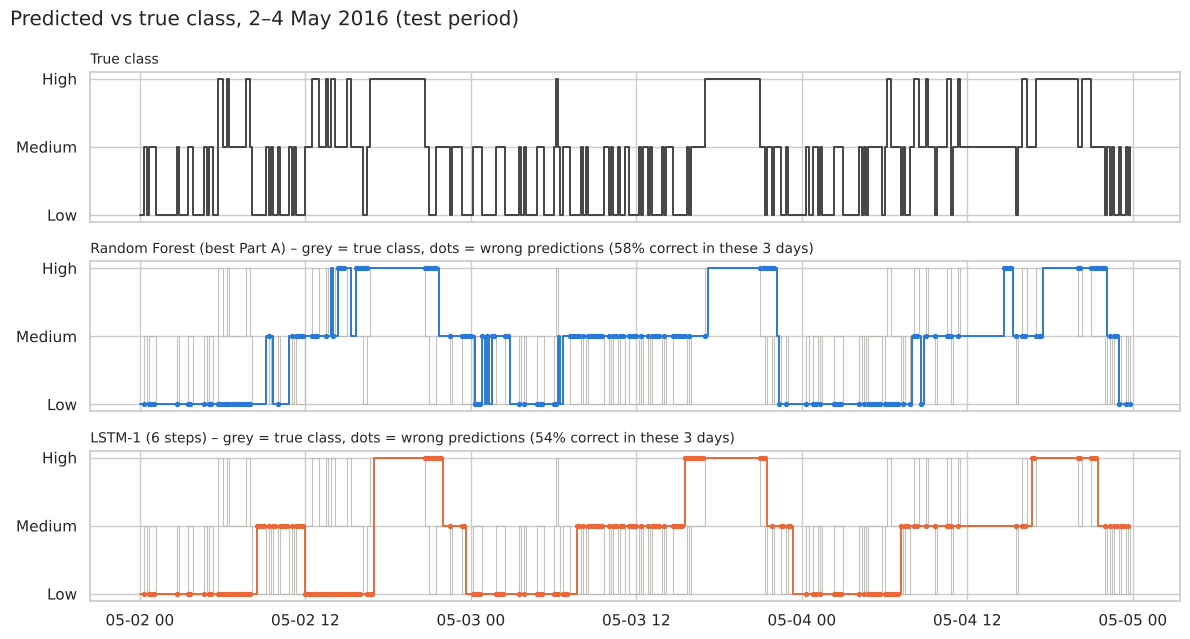

In [22]:
# Predictions over three days of the test period
best_lstm = results_B.drop(f"{best_A} (best Part A)")["test_accuracy"].idxmax().split(" (")[0]
window = (dates_test >= "2016-05-02") & (dates_test < "2016-05-05")
d = dates_test[window]
fig, axes = plt.subplots(3, 1, figsize=(12, 6.5), sharex=True)
for ax, (title, pred, c) in zip(axes, [("True class", y_test, COLOR_TEXT),
                                       (f"{best_A} (best Part A)", pred_A[best_A], COLOR_MAIN),
                                       (f"{best_lstm} ({SEQ_LENGTHS[best_lstm]} steps)", lstm_pred[best_lstm], COLOR_SECOND)]):
    if title != "True class":
        ax.step(d, y_test[window.to_numpy()], where="post", color=COLOR_GREY, linewidth=0.8, alpha=0.8)
    ax.step(d, pred[window.to_numpy()], where="post", color=c, linewidth=1.4)
    if title != "True class":
        wrong = pred[window.to_numpy()] != y_test[window.to_numpy()]
        ax.scatter(d[wrong], pred[window.to_numpy()][wrong], color=c, s=8, zorder=3)
        ax.set_title(f"{title} – grey = true class, dots = wrong predictions "
                     f"({100 * (1 - wrong.mean()):.0f}% correct in these 3 days)", loc="left", fontsize=10)
    else:
        ax.set_title(title, loc="left", fontsize=10)
    ax.set_yticks([0, 1, 2], CLASS_LABELS)
fig.suptitle("Predicted vs true class, 2–4 May 2016 (test period)", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "pa3_B4_predictions_over_time")
plt.show()

**Robustness check: is the difference between the models real?** A single training run of a neural network depends on its random initialisation, and the Random Forest on its random trees. Each model is therefore retrained with three more seeds (1, 2, 3) and the mean and standard deviation of the test accuracy are reported. *(Runtime: several minutes.)*

In [23]:
SEEDS = [RANDOM_STATE, 1, 2, 3]
seed_rows = []
for seed in SEEDS:
    for name, model in [("Random Forest", models_A["Random Forest"]), ("MLP Classifier", models_A["MLP Classifier"])]:
        m = clone(model).set_params(random_state=seed).fit(X_train_scaled, y_train)
        seed_rows.append({"model": name, "seed": seed, "test_accuracy": accuracy_score(y_test, m.predict(X_test_scaled))})
    for name in lstm_models:
        L = SEQ_LENGTHS[name]
        if seed == RANDOM_STATE:
            acc = results_B.loc[f"{name} ({L} steps)", "test_accuracy"]
        else:
            m, _, _ = train_lstm(L, BEST_BATCH, seed=seed, name=f"{name.replace('-', '_')}_seed{seed}")
            acc = m.evaluate(*seq_data[L]["test"], verbose=0)[1]
        seed_rows.append({"model": f"{name} ({L} steps)", "seed": seed, "test_accuracy": acc})
seed_results = pd.DataFrame(seed_rows)
seed_summary = seed_results.groupby("model", sort=False)["test_accuracy"].agg(["mean", "std", "min", "max"])
display(seed_results.pivot(index="model", columns="seed", values="test_accuracy").round(4))
display(seed_summary.round(4))

seed,1,2,3,42
model,,,,
LSTM-1 (6 steps),0.5079,0.5447,0.5389,0.5361
LSTM-2 (18 steps),0.5058,0.5335,0.5148,0.5095
MLP Classifier,0.4954,0.5040,0.5377,0.4849
Random Forest,0.5291,0.5185,0.5227,0.5128


,mean,std,min,max
model,,,,
Random Forest,0.5208,0.0069,0.5128,0.5291
MLP Classifier,0.5055,0.0229,0.4849,0.5377
LSTM-1 (6 steps),0.5319,0.0164,0.5079,0.5447
LSTM-2 (18 steps),0.5159,0.0123,0.5058,0.5335


### B.4 – Did the LSTM outperform the traditional models? Why or why not?
**Yes – the 1-hour LSTM (LSTM-1) is the best model, but only by a small margin.**
- **Results on the same 5,921 test readings:**

| Model | Accuracy | Loss | Weighted F1 |
|---|---|---|---|
| **LSTM-1** | **53.61%** | **0.883** | **0.524** |
| Random Forest (best Part A) | 51.28% | 0.917 | 0.506 |
| LSTM-2 | 50.95% | 0.913 | 0.506 |

  LSTM-1 gains **+2.3 pp** accuracy and has a lower loss than the Random Forest. LSTM-2 only matches it.
- **Where the gain comes from:** LSTM-1 recognises **High** readings much better (recall **0.80** vs 0.69). A high-consumption event such as cooking builds up over the previous hour (lights on, kitchen temperature and humidity rising), and only a model that sees the sequence can use this build-up. On Low (0.39 vs 0.36) and Medium (0.44 vs 0.49) the two models are similar.
- **Is the difference real?** Over 4 random seeds:

| Model | Mean ± std | Range |
|---|---|---|
| LSTM-1 | **53.19% ± 1.64** | 50.8–54.5% |
| Random Forest | 52.08% ± 0.69 | 51.3–52.9% |
| LSTM-2 | 51.59% ± 1.23 | – |
| MLP | 50.55% ± 2.29 | – |

  LSTM-1 is ahead on average (+1.1 pp), but the ranges overlap and the LSTM varies more between training runs. The advantage is consistent but modest.
- **Why the gain is not larger:**
  1. **Seasonal shift.** The shift between the winter training data and the spring test data limits every model to 51–54%.
  2. **No past consumption.** The sequences only contain sensor readings. Appliance use is driven by people, and the sensors register it indirectly and with a delay.
  3. **Time of day.** Much of the predictable pattern is the daily routine, which the Random Forest already gets from `hour_sin` and `hour_cos`.
- **What the predictions look like:** the 3-day figure shows that both models predict smooth blocks that follow the daily routine (Low at night, Medium during the day, High in the evening). The true class switches every 20–70 minutes. The LSTM's High blocks match the evening peaks better, but neither model captures the fast switching.